# Section 6. Dynamic Hedge Trading

In [21]:
# ============================================================
# Section 6. Dynamic Hedge Trading
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dataclasses import dataclass

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", "{:,.6f}".format)

SEED = 42
np.random.seed(SEED)

In [22]:
# ============================================================
# 6-0. Project Directory Setting
# ============================================================

PROJECT_NAME = "ELS hege 5.19"
CURRENT_DIR = Path.cwd()


def find_project_dir(project_name=PROJECT_NAME):
    """
    Resolve the local project folder from the notebook folder, a subfolder,
    or the parent workspace folder.
    """
    current = Path.cwd().resolve()

    if current.name == project_name:
        return current

    for parent in current.parents:
        if parent.name == project_name:
            return parent

    for base in [current, *current.parents]:
        candidate = base / project_name
        if candidate.exists():
            return candidate.resolve()

    return current / project_name


PROJECT_DIR = find_project_dir()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
FIGURE_DIR = PROJECT_DIR / "figures"
CODE_DIR = PROJECT_DIR

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

KOSPI200_PATH = DATA_DIR / "kospi200_close_new.csv"

print("CURRENT_DIR:", CURRENT_DIR)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)
print("CODE_DIR:", CODE_DIR)
print("KOSPI200_PATH:", KOSPI200_PATH)
print("Data file exists:", KOSPI200_PATH.exists())


CURRENT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
PROJECT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
DATA_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data
OUTPUT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output
FIGURE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures
CODE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
KOSPI200_PATH: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data\kospi200_close_new.csv
Data file exists: True


In [23]:
# ============================================================
# 6-1. ELS Product Specification
# ============================================================

@dataclass
class ELSProduct:
    underlying: str
    notional: float
    issue_date: str
    maturity_date: str
    payment_date: str
    
    annual_coupon: float
    maturity_years: float
    
    autocall_dates: list
    autocall_barriers: list
    
    knock_in_barrier: float
    max_loss_rate: float


els = ELSProduct(
    underlying="KOSPI200",
    notional=10_000_000_000,
    
    issue_date="2026-05-14",
    maturity_date="2029-05-09",
    payment_date="2029-05-14",
    
    annual_coupon=0.097,
    maturity_years=3.0,
    
    autocall_dates=[
        "2026-11-10",
        "2027-05-10",
        "2027-11-09",
        "2028-05-09",
        "2028-11-09",
        "2029-05-09",
    ],
    
    autocall_barriers=[0.85, 0.85, 0.85, 0.80, 0.75, 0.70],
    
    knock_in_barrier=0.35,
    max_loss_rate=-1.00
)

NOTIONAL = els.notional
S0 = 100
PRINCIPAL_DAILY_RATE = 0.03 / 365

els

ELSProduct(underlying='KOSPI200', notional=10000000000, issue_date='2026-05-14', maturity_date='2029-05-09', payment_date='2029-05-14', annual_coupon=0.097, maturity_years=3.0, autocall_dates=['2026-11-10', '2027-05-10', '2027-11-09', '2028-05-09', '2028-11-09', '2029-05-09'], autocall_barriers=[0.85, 0.85, 0.85, 0.8, 0.75, 0.7], knock_in_barrier=0.35, max_loss_rate=-1.0)

In [24]:
# ============================================================
# 6-2. Load Previous Section Outputs
# ============================================================

# Monte Carlo paths
paths = np.load(OUTPUT_DIR / "mc_paths.npy")

# Simulation dates
sim_dates = pd.read_csv(OUTPUT_DIR / "sim_dates.csv")
sim_dates["Date"] = pd.to_datetime(sim_dates["Date"])
sim_dates = pd.DatetimeIndex(sim_dates["Date"])

# Market params
market_params = pd.read_csv(OUTPUT_DIR / "market_params.csv").iloc[0].to_dict()

SIGMA = float(market_params["SIGMA"])
RISK_FREE_RATE = float(market_params["RISK_FREE_RATE"])
MU = float(market_params["MU"])
TRADING_DAYS = int(market_params["TRADING_DAYS"])

# Payoff result
payoff_df = pd.read_csv(OUTPUT_DIR / "els_payoff_result.csv")

# Experiment grid
experiment_grid = pd.read_csv(OUTPUT_DIR / "experiment_grid.csv")
experiment_grid = experiment_grid.copy()
experiment_grid["experiment_id"] = np.arange(len(experiment_grid))

# FDM outputs
S_GRID = np.load(OUTPUT_DIR / "fdm_S_GRID.npy")
delta_ki_grid = np.load(OUTPUT_DIR / "fdm_delta_ki_grid.npy")
delta_noki_grid = np.load(OUTPUT_DIR / "fdm_delta_noki_grid.npy")
V_ki_grid = np.load(OUTPUT_DIR / "fdm_V_ki_grid.npy")
V_noki_grid = np.load(OUTPUT_DIR / "fdm_V_noki_grid.npy")

print("paths shape:", paths.shape)
print("delta_noki_grid shape:", delta_noki_grid.shape)
print("Number of experiments:", len(experiment_grid))
print("SIGMA:", SIGMA)
print("RISK_FREE_RATE:", RISK_FREE_RATE)

display(payoff_df.head())
display(experiment_grid.head())

paths shape: (10000, 757)
delta_noki_grid shape: (757, 501)
Number of experiments: 33
SIGMA: 0.2720417549189577
RISK_FREE_RATE: 0.03


,path_id,autocall_occurred,autocall_no,settlement_index,elapsed_years,knock_in_occurred,final_price,min_price,payoff_type,investor_payoff,issuer_cash_outflow,investor_return_rate
0,0,True,1,128,0.507937,False,77.126761,73.599342,autocall_1,"10,492,698,412.698414","10,492,698,412.698414",0.049270
1,1,True,1,128,0.507937,False,443.679096,99.683350,autocall_1,"10,492,698,412.698414","10,492,698,412.698414",0.049270
2,2,True,1,128,0.507937,False,104.305185,80.462421,autocall_1,"10,492,698,412.698414","10,492,698,412.698414",0.049270
3,3,True,1,128,0.507937,False,119.838869,90.907308,autocall_1,"10,492,698,412.698414","10,492,698,412.698414",0.049270
4,4,True,1,128,0.507937,False,104.396985,66.499040,autocall_1,"10,492,698,412.698414","10,492,698,412.698414",0.049270


,principal_book_ratio,hedge_book_ratio,principal_book_amount,hedge_book_amount,static_ratio,dynamic_ratio,static_budget,dynamic_budget,experiment_id
0,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.000000,1.000000,0.000000,"7,000,000,000.000000",0
1,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.100000,0.900000,"700,000,000.000000","6,300,000,000.000000",1
2,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.200000,0.800000,"1,400,000,000.000000","5,600,000,000.000000",2
3,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.300000,0.700000,"2,100,000,000.000000","4,900,000,000.000000",3
4,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.400000,0.600000,"2,800,000,000.000000","4,200,000,000.000000",4


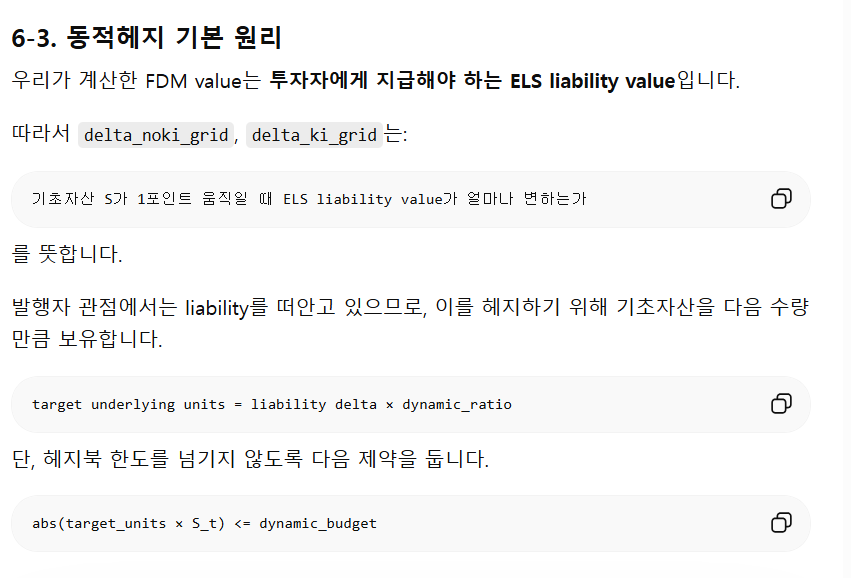

In [25]:
# ============================================================
# 6-4. Weekly Rebalancing Schedule
# ============================================================

N_PATHS, N_TIME = paths.shape
N_STEPS = N_TIME - 1

# 5거래일마다 리밸런싱
REBALANCE_FREQ = 5

weekly_rebal_indices = np.arange(0, N_STEPS + 1, REBALANCE_FREQ)

# settlement index도 반드시 포함해야 조기상환 시점에 청산 가능
settlement_indices = payoff_df["settlement_index"].astype(int).unique()

# 최종 만기도 포함
trading_indices = np.unique(
    np.concatenate([
        weekly_rebal_indices,
        settlement_indices,
        np.array([N_STEPS])
    ])
)

trading_indices = np.sort(trading_indices)

print("Number of trading indices:", len(trading_indices))
print("First 10 trading indices:", trading_indices[:10])
print("Last 10 trading indices:", trading_indices[-10:])

Number of trading indices: 157
First 10 trading indices: [ 0  5 10 15 20 25 30 35 40 45]
Last 10 trading indices: [715 720 725 730 735 740 745 750 755 756]


In [26]:
# ============================================================
# 6-5. Knock-in State Matrix
# ============================================================

ki_level = els.knock_in_barrier * S0

# 각 시점까지의 누적 최저가격
running_min_paths = np.minimum.accumulate(paths, axis=1)

# True면 해당 시점까지 이미 knock-in 발생
ki_state_matrix = running_min_paths <= ki_level

print("ki_state_matrix shape:", ki_state_matrix.shape)
print("Total KI probability at maturity:", ki_state_matrix[:, -1].mean())

ki_state_matrix shape: (10000, 757)
Total KI probability at maturity: 0.0249


In [27]:
# ============================================================
# 6-6. Delta Lookup Function
# ============================================================

def lookup_delta_vectorized(
    S_values,
    time_index,
    ki_states,
    S_GRID,
    delta_ki_grid,
    delta_noki_grid
):
    """
    path별 S, KI state에 따라 FDM delta를 보간해 가져온다.
    
    Parameters
    ----------
    S_values : np.ndarray
        shape = (n_paths,)
    time_index : int
        현재 time index
    ki_states : np.ndarray
        shape = (n_paths,), True면 KI state
    """
    
    time_index = int(np.clip(time_index, 0, delta_ki_grid.shape[0] - 1))
    
    S_clipped = np.clip(S_values, S_GRID[0], S_GRID[-1])
    
    delta_noki = np.interp(
        S_clipped,
        S_GRID,
        delta_noki_grid[time_index, :]
    )
    
    delta_ki = np.interp(
        S_clipped,
        S_GRID,
        delta_ki_grid[time_index, :]
    )
    
    delta = np.where(ki_states, delta_ki, delta_noki)
    
    return delta

In [28]:
# Test
test_delta = lookup_delta_vectorized(
    S_values=np.array([100, 80, 60, 40]),
    time_index=0,
    ki_states=np.array([False, False, False, False]),
    S_GRID=S_GRID,
    delta_ki_grid=delta_ki_grid,
    delta_noki_grid=delta_noki_grid
)

test_delta

array([-2.88157183e+06,  1.26220537e+07,  1.04803541e+08,  2.98768707e+08])

In [29]:
# ============================================================
# 6-7. Cash Growth Factor
# ============================================================

def cash_growth_factor_by_days(n_days, daily_rate=PRINCIPAL_DAILY_RATE):
    """
    n_days 동안 하루 단위 복리 운용.
    """
    return (1 + daily_rate) ** n_days

In [30]:
# ============================================================
# 6-8. Dynamic Hedge Trading Function
# ============================================================

def run_dynamic_hedge_for_experiment(
    row,
    paths,
    payoff_df,
    trading_indices,
    ki_state_matrix,
    S_GRID,
    delta_ki_grid,
    delta_noki_grid,
    principal_daily_rate=PRINCIPAL_DAILY_RATE
):
    """
    하나의 experiment에 대해 path별 dynamic hedge trading을 수행한다.
    
    핵심 구조:
    - dynamic_budget을 초기 hedge account cash로 둔다.
    - weekly rebalancing으로 FDM delta를 따라간다.
    - target_units = liability_delta * dynamic_ratio
    - 단, abs(target_units * S_t) <= dynamic_budget 으로 cap한다.
    - 조기상환 또는 만기 settlement 시 position을 청산한다.
    - settlement 이후 cash는 만기까지 원금북처럼 운용된다.
    
    Returns
    -------
    terminal_account : np.ndarray
        path별 dynamic hedge account 최종 잔고
    terminal_pnl : np.ndarray
        idle cash 대비 초과 PnL
    metadata : dict
        experiment별 요약 정보
    """
    
    n_paths, n_time = paths.shape
    n_steps = n_time - 1
    
    dynamic_ratio = float(row["dynamic_ratio"])
    dynamic_budget = float(row["dynamic_budget"])
    
    settlement_index = payoff_df["settlement_index"].astype(int).values
    
    # 초기 dynamic hedge account
    cash = np.full(n_paths, dynamic_budget, dtype=float)
    units = np.zeros(n_paths, dtype=float)
    
    active = np.ones(n_paths, dtype=bool)
    
    max_abs_position_value = np.zeros(n_paths)
    num_rebalances = np.zeros(n_paths, dtype=int)
    cap_binding_count = np.zeros(n_paths, dtype=int)
    
    last_idx = 0
    
    for idx in trading_indices:
        idx = int(idx)
        
        # 1. 직전 trading index부터 현재 index까지 cash 이자 반영
        n_days = idx - last_idx
        if n_days > 0:
            cash *= cash_growth_factor_by_days(
                n_days=n_days,
                daily_rate=principal_daily_rate
            )
        
        S_t = paths[:, idx]
        
        # 2. 현재 idx에서 settlement 되는 path는 position 청산 후 inactive
        settle_now = active & (settlement_index == idx)
        
        if np.any(settle_now):
            cash[settle_now] += units[settle_now] * S_t[settle_now]
            units[settle_now] = 0.0
            active[settle_now] = False
        
        # 3. 아직 살아있는 path만 weekly rebalancing
        rebalance_now = active
        
        if np.any(rebalance_now):
            S_active = S_t[rebalance_now]
            ki_active = ki_state_matrix[rebalance_now, idx]
            
            liability_delta = lookup_delta_vectorized(
                S_values=S_active,
                time_index=idx,
                ki_states=ki_active,
                S_GRID=S_GRID,
                delta_ki_grid=delta_ki_grid,
                delta_noki_grid=delta_noki_grid
            )
            
            # full delta hedge에 dynamic_ratio를 곱함
            target_units_uncapped = liability_delta * dynamic_ratio
            
            # hedge book 제약: abs(units * S) <= dynamic_budget
            position_value_uncapped = target_units_uncapped * S_active
            abs_position_value = np.abs(position_value_uncapped)
            
            cap_factor = np.ones_like(target_units_uncapped)
            binding = abs_position_value > dynamic_budget
            
            cap_factor[binding] = dynamic_budget / (abs_position_value[binding] + 1e-12)
            
            target_units = target_units_uncapped * cap_factor
            
            # 기존 units와 target units의 차이만큼 거래
            old_units = units[rebalance_now]
            trade_units = target_units - old_units
            
            # buy면 cash 감소, sell이면 cash 증가
            cash[rebalance_now] -= trade_units * S_active
            units[rebalance_now] = target_units
            
            # 기록
            max_abs_position_value[rebalance_now] = np.maximum(
                max_abs_position_value[rebalance_now],
                np.abs(target_units * S_active)
            )
            
            num_rebalances[rebalance_now] += 1
            cap_binding_count[rebalance_now] += binding.astype(int)
        
        last_idx = idx
    
    # 혹시 마지막까지 active인 path는 만기에서 청산
    final_S = paths[:, -1]
    still_active = active
    
    if np.any(still_active):
        cash[still_active] += units[still_active] * final_S[still_active]
        units[still_active] = 0.0
        active[still_active] = False
    
    terminal_account = cash
    
    # dynamic budget을 아무것도 안 하고 원금북처럼 굴렸을 때의 최종값
    idle_terminal_account = dynamic_budget * cash_growth_factor_by_days(
        n_days=n_steps,
        daily_rate=principal_daily_rate
    )
    
    terminal_pnl = terminal_account - idle_terminal_account
    
    metadata = {
        "dynamic_ratio": dynamic_ratio,
        "dynamic_budget": dynamic_budget,
        "mean_max_abs_position_value": np.mean(max_abs_position_value),
        "max_abs_position_value": np.max(max_abs_position_value),
        "mean_num_rebalances": np.mean(num_rebalances),
        "mean_cap_binding_count": np.mean(cap_binding_count),
        "cap_binding_path_ratio": np.mean(cap_binding_count > 0),
        "idle_terminal_account": idle_terminal_account,
    }
    
    return terminal_account, terminal_pnl, metadata

In [31]:
# ============================================================
# 6-9. Run Dynamic Hedge for All Experiments
# ============================================================

n_experiments = len(experiment_grid)
n_paths = paths.shape[0]

dynamic_terminal_account_matrix = np.zeros((n_experiments, n_paths))
dynamic_terminal_pnl_matrix = np.zeros((n_experiments, n_paths))

dynamic_metadata_list = []

for i, row in experiment_grid.iterrows():
    
    terminal_account, terminal_pnl, metadata = run_dynamic_hedge_for_experiment(
        row=row,
        paths=paths,
        payoff_df=payoff_df,
        trading_indices=trading_indices,
        ki_state_matrix=ki_state_matrix,
        S_GRID=S_GRID,
        delta_ki_grid=delta_ki_grid,
        delta_noki_grid=delta_noki_grid,
        principal_daily_rate=PRINCIPAL_DAILY_RATE
    )
    
    dynamic_terminal_account_matrix[i, :] = terminal_account
    dynamic_terminal_pnl_matrix[i, :] = terminal_pnl
    
    dynamic_metadata = {
        "experiment_id": int(row["experiment_id"]),
        "principal_book_ratio": row["principal_book_ratio"],
        "hedge_book_ratio": row["hedge_book_ratio"],
        "static_ratio": row["static_ratio"],
        "dynamic_ratio": row["dynamic_ratio"],
        "static_budget": row["static_budget"],
        "dynamic_budget": row["dynamic_budget"],
        **metadata
    }
    
    dynamic_metadata_list.append(dynamic_metadata)
    
    if i % 5 == 0:
        print(f"Finished experiment {i + 1} / {n_experiments}")

dynamic_metadata_df = pd.DataFrame(dynamic_metadata_list)

print("dynamic_terminal_account_matrix shape:", dynamic_terminal_account_matrix.shape)
print("dynamic_terminal_pnl_matrix shape:", dynamic_terminal_pnl_matrix.shape)

display(dynamic_metadata_df.head())

Finished experiment 1 / 33
Finished experiment 6 / 33
Finished experiment 11 / 33
Finished experiment 16 / 33
Finished experiment 21 / 33
Finished experiment 26 / 33
Finished experiment 31 / 33
dynamic_terminal_account_matrix shape: (33, 10000)
dynamic_terminal_pnl_matrix shape: (33, 10000)


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,static_budget,dynamic_budget,mean_max_abs_position_value,max_abs_position_value,mean_num_rebalances,mean_cap_binding_count,cap_binding_path_ratio,idle_terminal_account
0,0,0.300000,0.700000,0.000000,1.000000,0.000000,"7,000,000,000.000000","2,052,709,063.674867","7,000,000,000.000002",42.921300,2.773600,0.104200,"7,448,737,700.953319"
1,1,0.300000,0.700000,0.100000,0.900000,"700,000,000.000000","6,300,000,000.000000","1,847,438,157.307380","6,300,000,000.000002",42.921300,2.773600,0.104200,"6,703,863,930.857986"
2,2,0.300000,0.700000,0.200000,0.800000,"1,400,000,000.000000","5,600,000,000.000000","1,642,167,250.939894","5,600,000,000.000002",42.921300,2.773600,0.104200,"5,958,990,160.762655"
3,3,0.300000,0.700000,0.300000,0.700000,"2,100,000,000.000000","4,900,000,000.000000","1,436,896,344.572407","4,900,000,000.000001",42.921300,2.773600,0.104200,"5,214,116,390.667323"
4,4,0.300000,0.700000,0.400000,0.600000,"2,800,000,000.000000","4,200,000,000.000000","1,231,625,438.204920","4,200,000,000.000001",42.921300,2.773600,0.104200,"4,469,242,620.571991"


In [32]:
# ============================================================
# 6-10. Dynamic Hedge Performance Summary
# ============================================================

dynamic_perf_summary = []

for i, row in dynamic_metadata_df.iterrows():
    account = dynamic_terminal_account_matrix[i, :]
    pnl = dynamic_terminal_pnl_matrix[i, :]
    
    dynamic_perf_summary.append({
        "experiment_id": row["experiment_id"],
        "principal_book_ratio": row["principal_book_ratio"],
        "hedge_book_ratio": row["hedge_book_ratio"],
        "static_ratio": row["static_ratio"],
        "dynamic_ratio": row["dynamic_ratio"],
        "dynamic_budget": row["dynamic_budget"],
        "idle_terminal_account": row["idle_terminal_account"],
        "mean_terminal_account": np.mean(account),
        "std_terminal_account": np.std(account, ddof=1),
        "p05_terminal_account": np.percentile(account, 5),
        "p50_terminal_account": np.percentile(account, 50),
        "p95_terminal_account": np.percentile(account, 95),
        "min_terminal_account": np.min(account),
        "max_terminal_account": np.max(account),
        "mean_dynamic_pnl": np.mean(pnl),
        "std_dynamic_pnl": np.std(pnl, ddof=1),
        "p05_dynamic_pnl": np.percentile(pnl, 5),
        "p50_dynamic_pnl": np.percentile(pnl, 50),
        "p95_dynamic_pnl": np.percentile(pnl, 95),
        "min_dynamic_pnl": np.min(pnl),
        "max_dynamic_pnl": np.max(pnl),
        "mean_max_abs_position_value": row["mean_max_abs_position_value"],
        "max_abs_position_value": row["max_abs_position_value"],
        "mean_num_rebalances": row["mean_num_rebalances"],
        "mean_cap_binding_count": row["mean_cap_binding_count"],
        "cap_binding_path_ratio": row["cap_binding_path_ratio"],
    })

dynamic_perf_summary = pd.DataFrame(dynamic_perf_summary)

display(dynamic_perf_summary.head(15))

,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,dynamic_budget,idle_terminal_account,mean_terminal_account,std_terminal_account,p05_terminal_account,p50_terminal_account,p95_terminal_account,min_terminal_account,max_terminal_account,mean_dynamic_pnl,std_dynamic_pnl,p05_dynamic_pnl,p50_dynamic_pnl,p95_dynamic_pnl,min_dynamic_pnl,max_dynamic_pnl,mean_max_abs_position_value,max_abs_position_value,mean_num_rebalances,mean_cap_binding_count,cap_binding_path_ratio
0,0.000000,0.300000,0.700000,0.000000,1.000000,"7,000,000,000.000000","7,448,737,700.953319","7,460,814,182.154364","590,906,152.017926","7,318,517,619.212112","7,394,460,232.869972","8,413,144,968.033603","1,432,415,785.835474","9,736,157,565.173271","12,076,481.201045","590,906,152.017926","-130,220,081.741206","-54,277,468.083347","964,407,267.080284","-6,016,321,915.117846","2,287,419,864.219953","2,052,709,063.674867","7,000,000,000.000002",42.921300,2.773600,0.104200
1,1.000000,0.300000,0.700000,0.100000,0.900000,"6,300,000,000.000000","6,703,863,930.857986","6,714,732,763.938928","531,815,536.816134","6,586,665,857.290908","6,655,014,209.582975","7,571,830,471.230257","1,289,174,207.251930","8,762,541,808.655943","10,868,833.080942","531,815,536.816134","-117,198,073.567079","-48,849,721.275011","867,966,540.372270","-5,414,689,723.606056","2,058,677,877.797956","1,847,438,157.307380","6,300,000,000.000002",42.921300,2.773600,0.104200
2,2.000000,0.300000,0.700000,0.200000,0.800000,"5,600,000,000.000000","5,958,990,160.762655","5,968,651,345.723491","472,724,921.614341","5,854,814,095.369696","5,915,568,186.295974","6,730,515,974.426892","1,145,932,628.668379","7,788,926,052.138615","9,661,184.960836","472,724,921.614341","-104,176,065.392960","-43,421,974.466681","771,525,813.664237","-4,813,057,532.094276","1,829,935,891.375959","1,642,167,250.939894","5,600,000,000.000002",42.921300,2.773600,0.104200
3,3.000000,0.300000,0.700000,0.300000,0.700000,"4,900,000,000.000000","5,214,116,390.667323","5,222,569,927.508055","413,634,306.412548","5,122,962,333.448480","5,176,122,163.008982","5,889,201,477.623534","1,002,691,050.084834","6,815,310,295.621291","8,453,536.840731","413,634,306.412548","-91,154,057.218844","-37,994,227.658342","675,085,086.956211","-4,211,425,340.582489","1,601,193,904.953968","1,436,896,344.572407","4,900,000,000.000001",42.921300,2.773600,0.104200
4,4.000000,0.300000,0.700000,0.400000,0.600000,"4,200,000,000.000000","4,469,242,620.571991","4,476,488,509.292619","354,543,691.210756","4,391,110,571.527264","4,436,676,139.721985","5,047,886,980.820160","859,449,471.501283","5,841,694,539.103967","7,245,888.720628","354,543,691.210756","-78,132,049.044727","-32,566,480.850006","578,644,360.248169","-3,609,793,149.070708","1,372,451,918.531976","1,231,625,438.204920","4,200,000,000.000001",42.921300,2.773600,0.104200
5,5.000000,0.300000,0.700000,0.500000,0.500000,"3,500,000,000.000000","3,724,368,850.476659","3,730,407,091.077182","295,453,076.008963","3,659,258,809.606056","3,697,230,116.434986","4,206,572,484.016801","716,207,892.917737","4,868,078,782.586636","6,038,240.600523","295,453,076.008963","-65,110,040.870603","-27,138,734.041673","482,203,633.540142","-3,008,160,957.558923","1,143,709,932.109976","1,026,354,531.837434","3,500,000,000.000001",42.921300,2.773600,0.104200
6,6.000000,0.300000,0.700000,0.600000,0.400000,"2,800,000,000.000000","2,979,495,080.381327","2,984,325,672.861745","236,362,460.807171","2,927,407,047.684847","2,957,784,093.147986","3,365,257,987.213443","572,966,314.334189","3,894,463,026.069306","4,830,592.480418","236,362,460.807171","-52,088,032.696480","-21,710,987.233341","385,762,906.832116","-2,406,528,766.047138","914,967,945.687979","821,083,625.469947","2,800,000,000.000000",42.921300,2.773600,0.104200
7,7.000000,0.300000,0.700000,0.700000,0.300000,"2,100,000,000.000000","2,234,621,310.285995","2,238,244,254.646309","177,271,845.605378","2,195,555,285.763632","2,218,338,069.860

In [33]:
# ============================================================
# 6-11. Dynamic Performance by Dynamic Ratio
# ============================================================

dynamic_ratio_summary = (
    dynamic_perf_summary
    .groupby("dynamic_ratio")
    .agg(
        avg_mean_account=("mean_terminal_account", "mean"),
        avg_p05_account=("p05_terminal_account", "mean"),
        avg_mean_pnl=("mean_dynamic_pnl", "mean"),
        avg_p05_pnl=("p05_dynamic_pnl", "mean"),
        avg_std_pnl=("std_dynamic_pnl", "mean"),
        avg_cap_binding_path_ratio=("cap_binding_path_ratio", "mean"),
    )
    .reset_index()
)

dynamic_ratio_summary

,dynamic_ratio,avg_mean_account,avg_p05_account,avg_mean_pnl,avg_p05_pnl,avg_std_pnl,avg_cap_binding_path_ratio
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.100000,"533,001,091.627951","519,224,265.730438","948,398.702714","-12,828,427.194799","47,544,401.150234",0.169600
2,0.200000,"1,066,002,183.255903","1,038,448,531.460877","1,896,797.405429","-25,656,854.389597","95,088,802.300468",0.169600
3,0.300000,"1,599,003,274.883854","1,557,672,797.191315","2,845,196.108143","-38,485,281.584396","142,633,203.450702",0.169600
4,0.400000,"2,132,004,366.511806","2,076,897,062.921754","3,793,594.810858","-51,313,708.779194","190,177,604.600935",0.169600
5,0.500000,"2,665,005,458.139757","2,596,121,328.652193","4,741,993.513572","-64,142,135.973992","237,722,005.751169",0.169600
6,0.600000,"3,198,006,549.767709","3,115,345,594.382629","5,690,392.216287","-76,970,563.168793","285,266,406.901403",0.169600
7,0.700000,"3,731,007,641.395660","3,634,569,860.113070","6,638,790.919001","-89,798,990.363589","332,810,808.051637",0.169600
8,0.800000,"4,264,008,733.023612","4,153,794,125.843508","7,587,189.621715","-102,627,417.558388","380,355,209.201871",0.169600
9,0.900000,"4,797,009,824.651564","4,673,018,391.573949","8,535,588.324430","-115,455,844.753185","427,899,610.352105",0.169600


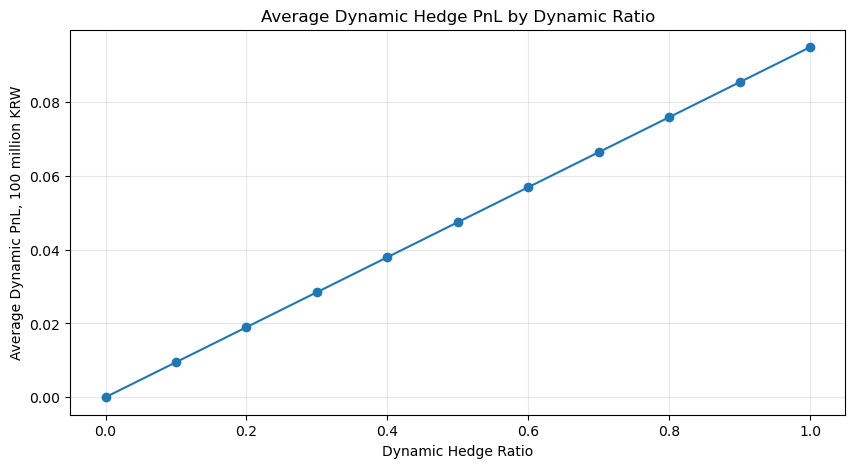

In [34]:
# ============================================================
# 6-12. Plot Dynamic Hedge Mean PnL by Dynamic Ratio
# ============================================================

plt.figure(figsize=(10, 5))
plt.plot(
    dynamic_ratio_summary["dynamic_ratio"],
    dynamic_ratio_summary["avg_mean_pnl"] / 1e8,
    marker="o"
)
plt.title("Average Dynamic Hedge PnL by Dynamic Ratio")
plt.xlabel("Dynamic Hedge Ratio")
plt.ylabel("Average Dynamic PnL, 100 million KRW")
plt.grid(True, alpha=0.3)
plt.show()

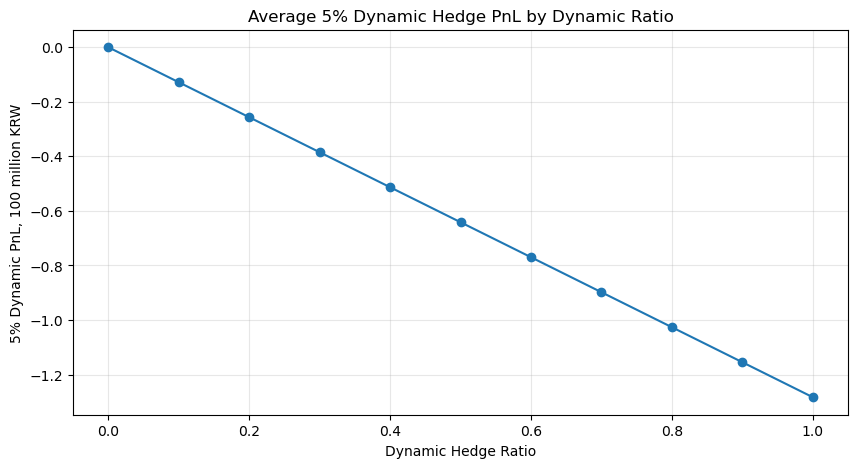

In [35]:
# ============================================================
# 6-12-1. Plot Dynamic Hedge 5% PnL by Dynamic Ratio
# ============================================================

plt.figure(figsize=(10, 5))
plt.plot(
    dynamic_ratio_summary["dynamic_ratio"],
    dynamic_ratio_summary["avg_p05_pnl"] / 1e8,
    marker="o"
)
plt.title("Average 5% Dynamic Hedge PnL by Dynamic Ratio")
plt.xlabel("Dynamic Hedge Ratio")
plt.ylabel("5% Dynamic PnL, 100 million KRW")
plt.grid(True, alpha=0.3)
plt.show()

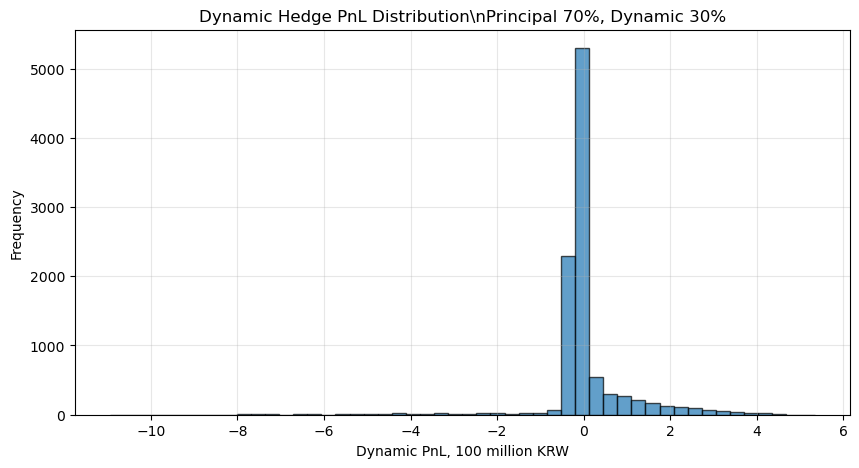

Experiment ID: 29


,experiment_id,principal_book_ratio,hedge_book_ratio,static_ratio,dynamic_ratio,static_budget,dynamic_budget,mean_max_abs_position_value,max_abs_position_value,mean_num_rebalances,mean_cap_binding_count,cap_binding_path_ratio,idle_terminal_account
29,29,0.700000,0.300000,0.700000,0.300000,"2,100,000,000.000000","900,000,000.000000","420,663,047.289824","900,000,000.000000",42.921300,6.679700,0.243300,"957,694,847.265427"


Mean PnL: 1964387.8982276947
5% PnL: -37110560.915517084
Min PnL: -1094733763.804343
Mean terminal account: 959659235.1636543


In [36]:
# ============================================================
# 6-13. Example Dynamic Hedge PnL Distribution
# ============================================================

example_row = dynamic_metadata_df[
    (dynamic_metadata_df["principal_book_ratio"] == 0.70)
    & (np.isclose(dynamic_metadata_df["dynamic_ratio"], 0.30))
]

if len(example_row) > 0:
    example_id = int(example_row.iloc[0]["experiment_id"])
    
    example_pnl = dynamic_terminal_pnl_matrix[example_id, :]
    example_account = dynamic_terminal_account_matrix[example_id, :]
    
    plt.figure(figsize=(10, 5))
    plt.hist(example_pnl / 1e8, bins=50, edgecolor="black", alpha=0.7)
    plt.title("Dynamic Hedge PnL Distribution\\nPrincipal 70%, Dynamic 30%")
    plt.xlabel("Dynamic PnL, 100 million KRW")
    plt.ylabel("Frequency")
    plt.grid(True, alpha=0.3)
    plt.show()
    
    print("Experiment ID:", example_id)
    display(example_row)
    print("Mean PnL:", example_pnl.mean())
    print("5% PnL:", np.percentile(example_pnl, 5))
    print("Min PnL:", example_pnl.min())
    print("Mean terminal account:", example_account.mean())

In [37]:
# ============================================================
# 6-14. Save Section 6 Outputs
# ============================================================

np.save(
    OUTPUT_DIR / "dynamic_terminal_account_matrix.npy",
    dynamic_terminal_account_matrix
)

np.save(
    OUTPUT_DIR / "dynamic_terminal_pnl_matrix.npy",
    dynamic_terminal_pnl_matrix
)

dynamic_metadata_path = OUTPUT_DIR / "dynamic_hedge_metadata.csv"
dynamic_perf_summary_path = OUTPUT_DIR / "dynamic_hedge_performance_summary.csv"
dynamic_ratio_summary_path = OUTPUT_DIR / "dynamic_hedge_ratio_summary.csv"

dynamic_metadata_df.to_csv(
    dynamic_metadata_path,
    index=False,
    encoding="utf-8-sig"
)

dynamic_perf_summary.to_csv(
    dynamic_perf_summary_path,
    index=False,
    encoding="utf-8-sig"
)

dynamic_ratio_summary.to_csv(
    dynamic_ratio_summary_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved dynamic terminal account matrix")
print("Saved dynamic terminal pnl matrix")
print("Saved dynamic metadata to:", dynamic_metadata_path)
print("Saved dynamic performance summary to:", dynamic_perf_summary_path)
print("Saved dynamic ratio summary to:", dynamic_ratio_summary_path)

Saved dynamic terminal account matrix
Saved dynamic terminal pnl matrix
Saved dynamic metadata to: c:\Users\Yeonsoo\Desktop\ELS hege 5.19\output\dynamic_hedge_metadata.csv
Saved dynamic performance summary to: c:\Users\Yeonsoo\Desktop\ELS hege 5.19\output\dynamic_hedge_performance_summary.csv
Saved dynamic ratio summary to: c:\Users\Yeonsoo\Desktop\ELS hege 5.19\output\dynamic_hedge_ratio_summary.csv
